In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Open this notebook from the project folder"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


# 01 Validation — SIR baseline (no behaviour)
Checks: beta=0 no spread, gamma=1 fast recovery, determinism, mean-field sanity.

0.0 0.033 peak 0.033 dur 53
0.06 0.98 peak 0.383 dur 126
0.12 1.0 peak 0.65 dur 118
0.2 1.0 peak 0.747 dur 118


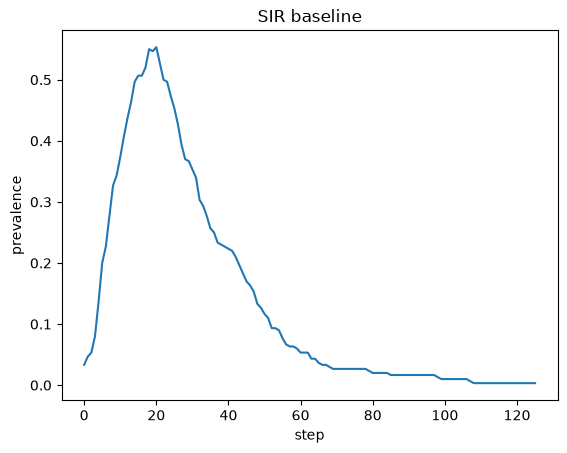

In [ ]:
from src.simulation import SimParams, run_coupled
import matplotlib.pyplot as plt

for beta in [0.0, 0.06, 0.12, 0.2]:
    out = run_coupled(SimParams(topology='ws', n=300, seed=0, beta=beta, rule='none'))
    print(beta, round(out['final_size'],3), 'peak', round(out['peak'],3), 'dur', out['duration'])

out = run_coupled(SimParams(topology='ws', n=300, seed=1, beta=0.12, rule='none'))
plt.plot(out['prev_series']); plt.xlabel('step'); plt.ylabel('prevalence'); plt.title('SIR baseline'); plt.show()

## Mean-field comparison (Issue #5)
The homogeneous ODE uses population fractions and incidence beta*k*s*i in BOTH the susceptible and infected equations. It is a reference approximation, not an exact network limit: the engine uses synchronous discrete-time Bernoulli transmission and recovery on a fixed clustered WS network, whereas the ODE assumes continuous time and homogeneous mixing. Setting continuous rates equal to per-step probabilities is a first-order approximation. Differences may reflect clustering, repeated contacts, stochasticity, and this time/parameter approximation; they cannot be attributed to clustering alone. Error bars show sample SD across 20 seeds, not confidence intervals.


Finished beta=0.03: 20 seeds
Finished beta=0.06: 20 seeds
Finished beta=0.12: 20 seeds
Finished beta=0.2: 20 seeds


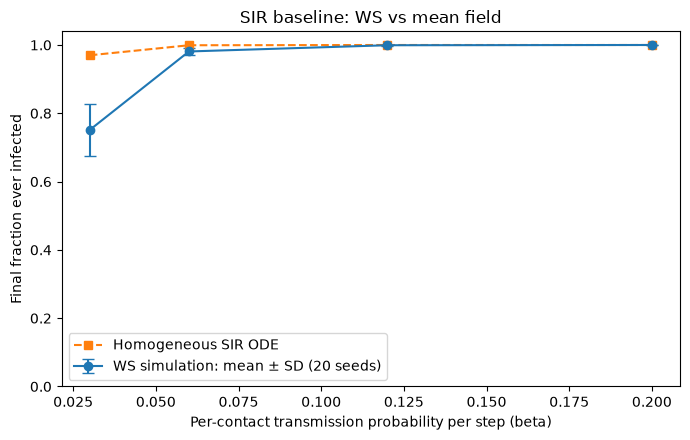

 beta    mean      std  ode_final_size
 0.03 0.75125 0.075067        0.969848
 0.06 0.98105 0.009191        0.999257
 0.12 0.99930 0.001129        0.999999
 0.20 1.00000 0.000000        1.000000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from src.simulation import SimParams, run_coupled

# Fractions s+i+r=1; beta and gamma are used as per-step rate approximations.
N, K, GAMMA, INITIAL = 1000, 6, 0.05, 10
BETAS = [0.03, 0.06, 0.12, 0.2]
def ode_final(beta):
    def rhs(t,y):
        s,i,r=y
        incidence=beta*K*s*i
        recovery=GAMMA*i
        return [-incidence, incidence-recovery, recovery]
    sol=solve_ivp(rhs,(0,5000),[1-INITIAL/N,INITIAL/N,0.],
                  rtol=1e-9,atol=1e-11)
    assert sol.success
    assert abs(sol.y[:, -1].sum()-1)<1e-7
    assert sol.y[1,-1]<1e-7
    return 1-sol.y[0,-1]

rows=[]
for beta in BETAS:
    for seed in range(20):
        out=run_coupled(SimParams(topology="ws",n=N,seed=seed,beta=beta,
            gamma=GAMMA,init_infected=INITIAL,rule="none",max_steps=2000))
        if out["duration"]>=2000:
            raise RuntimeError("Simulation reached the time cap; extend the horizon")
        rows.append({"beta":beta,"seed":seed,"final_size":out["final_size"]})
    print(f"Finished beta={beta}: 20 seeds")
runs=pd.DataFrame(rows)
summary=runs.groupby("beta")["final_size"].agg(["mean","std"]).reset_index()
summary["ode_final_size"]=[ode_final(b) for b in summary.beta]
folder=ROOT/"figures"
folder.mkdir(exist_ok=True)
runs.to_csv(folder/"mean_field_runs.csv",index=False)
summary.to_csv(folder/"mean_field_summary.csv",index=False)
fig,ax=plt.subplots(figsize=(7,4.5))
ax.errorbar(summary.beta,summary["mean"],yerr=summary["std"],fmt="o-",
            capsize=4,label="WS simulation: mean ± SD (20 seeds)")
ax.plot(summary.beta,summary.ode_final_size,"s--",label="Homogeneous SIR ODE")
ax.set(xlabel="Per-contact transmission probability per step (beta)",
       ylabel="Final fraction ever infected",ylim=(0,1.04),title="SIR baseline: WS vs mean field")
ax.legend(); fig.tight_layout()
fig.savefig(folder/"mean_field_validation.png",dpi=200)
fig.savefig(folder/"mean_field_validation.pdf")
plt.show()
print(summary.to_string(index=False))


At beta=0.03, the WS simulation infected 75.1% of nodes on average (SD 7.5 percentage points), compared with 97.0% under the homogeneous mean-field ODE. Both approaches approached complete infection at higher beta values. The difference is consistent with network contact constraints and clustering, but stochasticity and the discrete-time versus continuous-time approximation also contribute, so it cannot be attributed to clustering alone.